In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

In [2]:
data = load_breast_cancer(as_frame=True)

X = data.data
y = data.target

print("Размер датасета:", X.shape)
print("Количество признаков:", X.shape[1])
print("Классы:", data.target_names)

print("\nРаспределение классов:")
print(y.value_counts().rename(index={
    0: "malignant",
    1: "benign"
}))

display(X.head())

Размер датасета: (569, 30)
Количество признаков: 30
Классы: ['malignant' 'benign']

Распределение классов:
target
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=67,
    stratify=y
)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

Обучающая выборка: (455, 30)
Тестовая выборка: (114, 30)


In [8]:
tree = DecisionTreeClassifier(random_state=67)

forest = RandomForestClassifier(
    n_estimators=100,
    random_state=67,
    oob_score=True,
    n_jobs=-1
)

tree.fit(X_train, y_train)
forest.fit(X_train, y_train)

print("Дерево решений обучено.")
print("Случайный лес обучен.")
print("Количество деревьев:", len(forest.estimators_))
print("OOB score случайного леса:", round(forest.oob_score_, 4))

Дерево решений обучено.
Случайный лес обучен.
Количество деревьев: 100
OOB score случайного леса: 0.9582


In [7]:
tree_pred = tree.predict(X_test)
forest_pred = forest.predict(X_test)

results = pd.DataFrame([
    {
        "Model": "Decision Tree",
        "Accuracy": accuracy_score(y_test, tree_pred),
        "F1 macro": f1_score(
            y_test, tree_pred, average="macro"
        )
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, forest_pred),
        "F1 macro": f1_score(
            y_test, forest_pred, average="macro"
        )
    }
])

display(results.round(4))

print("Отчёт для случайного леса:")
print(classification_report(
    y_test,
    forest_pred,
    target_names=data.target_names
))

,Model,Accuracy,F1 macro
0,Decision Tree,0.9298,0.9246
1,Random Forest,0.9386,0.9337


Отчёт для случайного леса:
              precision    recall  f1-score   support

   malignant       0.93      0.90      0.92        42
      benign       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114



In [9]:
tree_pred = tree.predict(X_test)
forest_pred = forest.predict(X_test)

results = pd.DataFrame([
    {
        "Model": "Decision Tree",
        "Accuracy": accuracy_score(y_test, tree_pred),
        "F1 macro": f1_score(
            y_test, tree_pred, average="macro"
        )
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, forest_pred),
        "F1 macro": f1_score(
            y_test, forest_pred, average="macro"
        )
    }
])

display(results.round(4))

print("Отчёт для случайного леса:")
print(classification_report(
    y_test,
    forest_pred,
    target_names=data.target_names
))

,Model,Accuracy,F1 macro
0,Decision Tree,0.9211,0.9156
1,Random Forest,0.9386,0.9337


Отчёт для случайного леса:
              precision    recall  f1-score   support

   malignant       0.93      0.90      0.92        42
      benign       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114



Топ-10 важных признаков:


,Impurity importance
worst perimeter,0.161109
worst area,0.138483
worst radius,0.111975
worst concave points,0.103128
mean concave points,0.087666
area error,0.063995
mean perimeter,0.055715
mean radius,0.040472
worst concavity,0.039782
mean concavity,0.036239


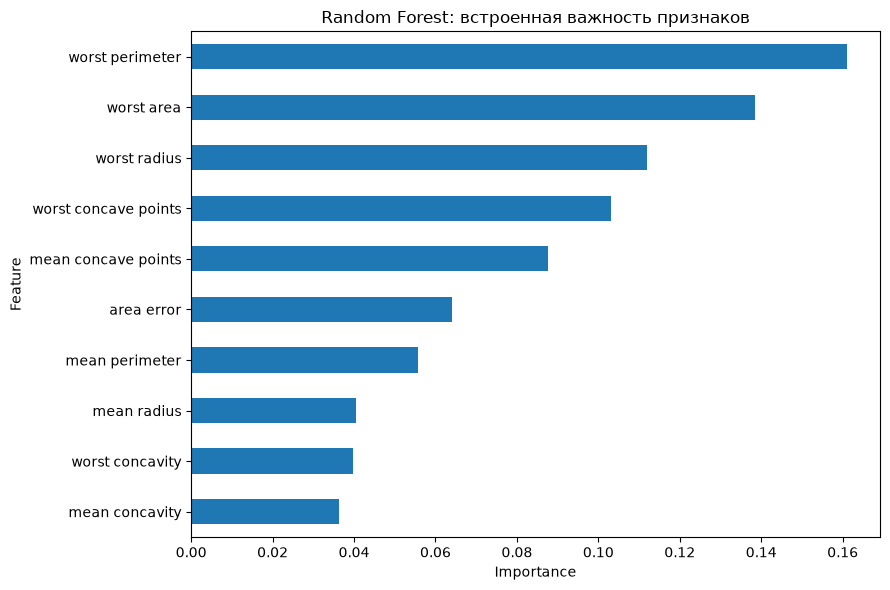

In [10]:
importances = pd.Series(
    forest.feature_importances_,
    index=X.columns,
    name="Impurity importance"
).sort_values(ascending=False)

print("Топ-10 важных признаков:")
display(importances.head(10).to_frame())

importances.head(10).sort_values().plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("Random Forest: встроенная важность признаков")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

* Этот метод оценивает важность признаков по тому, насколько они уменьшают неоднородность в узлах деревьев. Важно помнить, что такая оценка может завышать значимость признаков с большим числом возможных значений.

Топ-10 признаков по permutation importance:


,Permutation importance
radius error,0.008772
perimeter error,0.008772
worst symmetry,0.008772
area error,0.007018
worst compactness,0.007018
compactness error,0.005263
concave points error,0.005263
fractal dimension error,0.005263
symmetry error,0.005263
worst area,0.003509


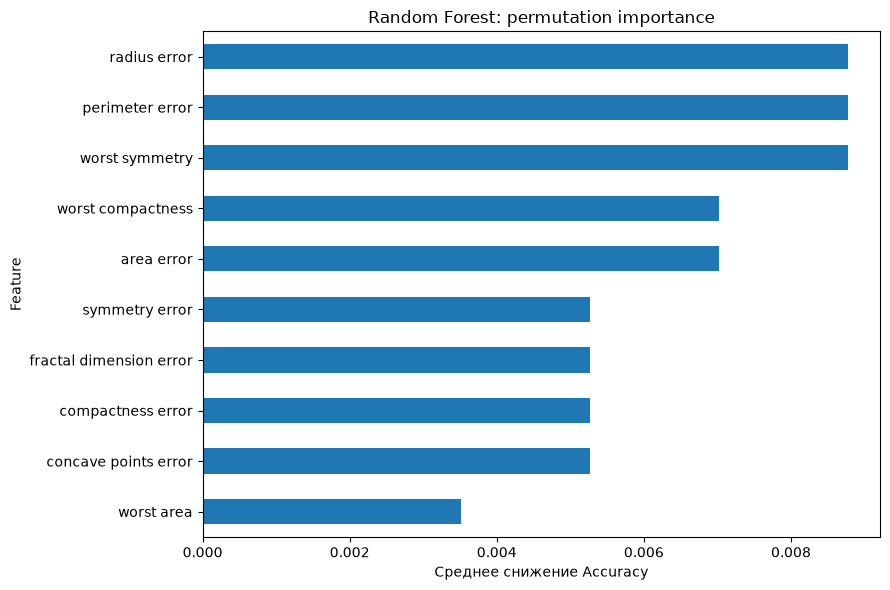

In [11]:
perm_result = permutation_importance(
    forest,
    X_test,
    y_test,
    scoring="accuracy",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

permutation_importances = pd.Series(
    perm_result.importances_mean,
    index=X.columns,
    name="Permutation importance"
).sort_values(ascending=False)

print("Топ-10 признаков по permutation importance:")
display(permutation_importances.head(10).to_frame())

permutation_importances.head(10).sort_values().plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("Random Forest: permutation importance")
plt.xlabel("Среднее снижение Accuracy")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [12]:
importance_comparison = pd.DataFrame({
    "Impurity importance": forest.feature_importances_,
    "Permutation importance": perm_result.importances_mean
}, index=X.columns)

importance_comparison["Impurity rank"] = (
    importance_comparison["Impurity importance"]
    .rank(ascending=False)
    .astype(int)
)

importance_comparison["Permutation rank"] = (
    importance_comparison["Permutation importance"]
    .rank(ascending=False)
    .astype(int)
)

importance_comparison = importance_comparison.sort_values(
    "Impurity importance",
    ascending=False
)

display(importance_comparison.head(10).round(4))

print(
    "Корреляция рангов:",
    round(
        importance_comparison["Impurity rank"].corr(
            importance_comparison["Permutation rank"],
            method="spearman"
        ),
        4
    )
)

,Impurity importance,Permutation importance,Impurity rank,Permutation rank
worst perimeter,0.1611,0.0018,1,15
worst area,0.1385,0.0035,2,11
worst radius,0.1120,0.0018,3,16
worst concave points,0.1031,0.0018,4,14
mean concave points,0.0877,-0.0070,5,30
area error,0.0640,0.0070,6,4
mean perimeter,0.0557,0.0000,7,23
mean radius,0.0405,0.0000,8,23
worst concavity,0.0398,0.0035,9,11
mean concavity,0.0362,0.0018,10,16


Корреляция рангов: -0.0563


In [13]:
explainer = shap.TreeExplainer(forest)

# Берём 50 тестовых объектов для общего анализа
X_shap = X_test.iloc[:50]
shap_values = explainer(X_shap)

print("Размер выборки для SHAP:", X_shap.shape)
print("Форма массива SHAP:", shap_values.values.shape)
print("Классы модели:", forest.classes_)

Размер выборки для SHAP: (50, 30)
Форма массива SHAP: (50, 30, 2)
Классы модели: [0 1]


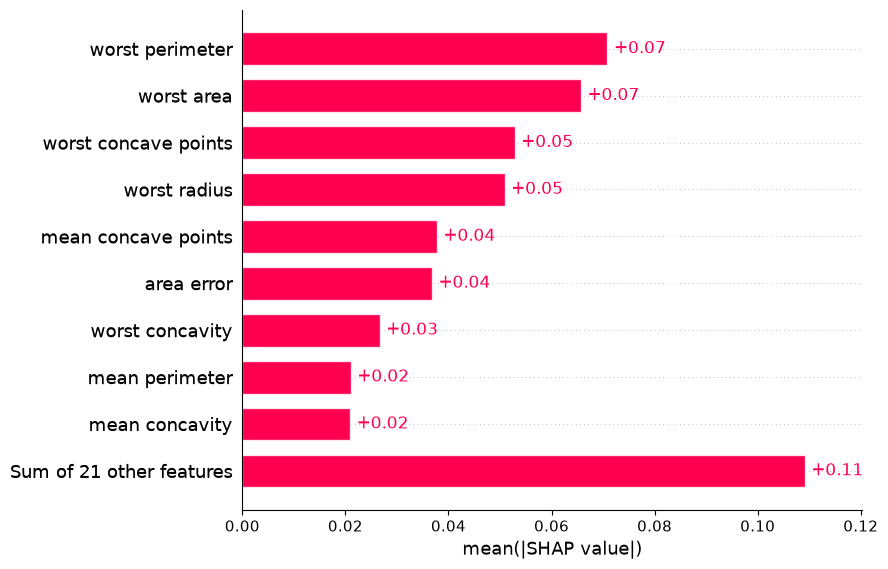

In [14]:
# Класс 1 — benign (доброкачественная опухоль)
shap.plots.bar(shap_values[:, :, 1], max_display=10)


Объект 1
Истинный класс: malignant
Предсказанный класс: malignant


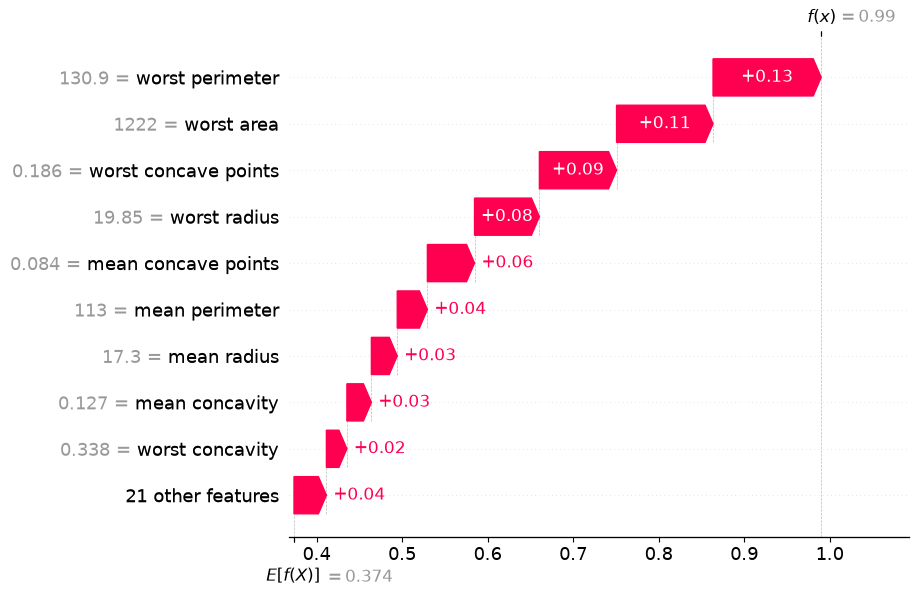


Объект 2
Истинный класс: benign
Предсказанный класс: benign


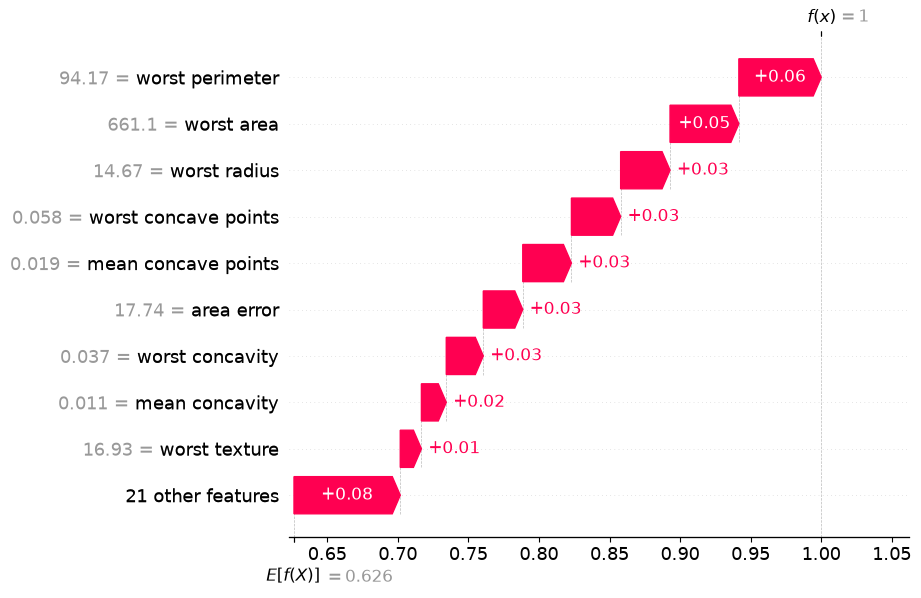


Объект 3
Истинный класс: malignant
Предсказанный класс: malignant


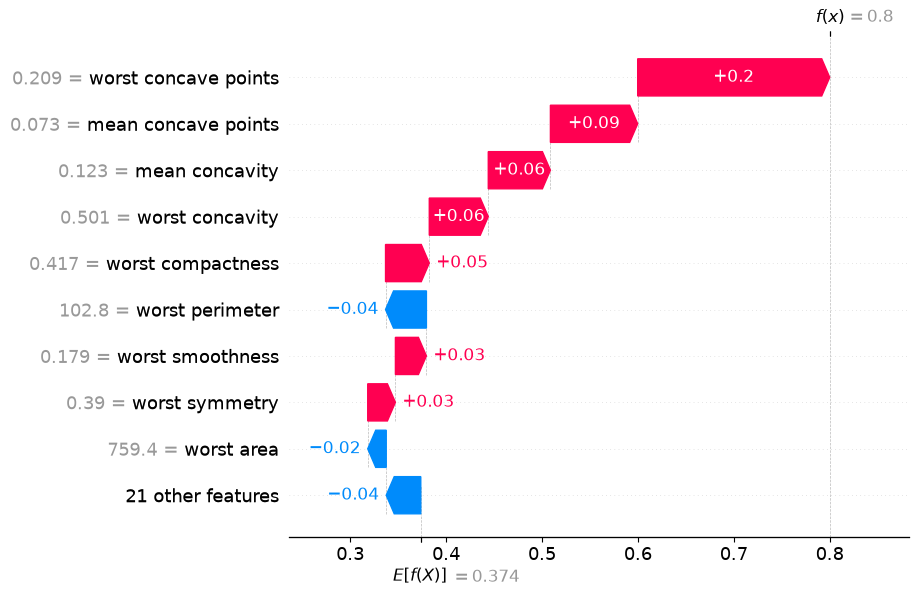

In [15]:
for i in range(3):
    sample = X_test.iloc[[i]]
    true_class = y_test.iloc[i]
    predicted_class = forest.predict(sample)[0]

    print(f"\nОбъект {i + 1}")
    print("Истинный класс:", data.target_names[true_class])
    print("Предсказанный класс:", data.target_names[predicted_class])

    shap.plots.waterfall(
        shap_values[i, :, predicted_class],
        max_display=10
    )

* Каждый waterfall-график объясняет одно предсказание. Признаки с положительным вкладом сдвигают результат в сторону выбранного класса, а с отрицательным — от него. Это объяснение поведения модели, а не доказательство причин возникновения заболевания.

In [16]:
print("=== ДАННЫЕ ===")
print("Всего объектов:", len(X))
print("Количество признаков:", X.shape[1])
print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

print("\n=== СРАВНЕНИЕ МОДЕЛЕЙ ===")
display(results.round(4))

print("Количество деревьев:", len(forest.estimators_))
print("OOB score:", round(forest.oob_score_, 4))

print("\n=== ТОП-2 ПО ВСТРОЕННОЙ ВАЖНОСТИ ===")
display(importances.head(2).to_frame())

print("\n=== ТОП-2 ПО PERMUTATION IMPORTANCE ===")
display(permutation_importances.head(2).to_frame())

print("\n=== ТОП-2 ПО SHAP ===")
shap_importance = pd.Series(
    abs(shap_values.values[:, :, 1]).mean(axis=0),
    index=X.columns
).sort_values(ascending=False)

display(shap_importance.head(2).to_frame("Mean absolute SHAP"))

print("\nКорреляция рангов Спирмена:",
      round(
          importance_comparison["Impurity rank"].corr(
              importance_comparison["Permutation rank"],
              method="spearman"
          ),
          4
      ))

=== ДАННЫЕ ===
Всего объектов: 569
Количество признаков: 30
Обучающая выборка: (455, 30)
Тестовая выборка: (114, 30)

=== СРАВНЕНИЕ МОДЕЛЕЙ ===


,Model,Accuracy,F1 macro
0,Decision Tree,0.9211,0.9156
1,Random Forest,0.9386,0.9337


Количество деревьев: 100
OOB score: 0.9582

=== ТОП-2 ПО ВСТРОЕННОЙ ВАЖНОСТИ ===


,Impurity importance
worst perimeter,0.161109
worst area,0.138483



=== ТОП-2 ПО PERMUTATION IMPORTANCE ===


,Permutation importance
radius error,0.008772
perimeter error,0.008772



=== ТОП-2 ПО SHAP ===


,Mean absolute SHAP
worst perimeter,0.070831
worst area,0.065683



Корреляция рангов Спирмена: -0.0563
